# Clustering Penguins in Antarctica

<img src="https://imgur.com/orZWHly.png" width="420" alt="Illustration of the three penguin species">

*Artwork by [@allison_horst](https://github.com/allisonhorst/penguins)*

This notebook explores how penguins can be grouped using their physical characteristics. It started as a DataCamp project, and I extended it by and I extended it by using the elbow method and silhouette scores to choose the number of clusters (k), and by adding a PCA to visualize and interpret the clusters.

**A note on AI use:** The code, the analysis, and the conclusions are my own work. I used AI (Claude) as a writing aid, to help me phrase my findings clearly and to tidy the notebook's formatting and comments.

## Context

A team of researchers has been collecting data on penguins in Antarctica. Unfortunately, they did not record the **species** of each bird. They know that **at least three** species live in the area: Adelie, Chinstrap and Gentoo. My job is to use unsupervised learning to find the groups hidden in the data.

The data comes from Dr. Kristen Gorman and the Palmer Station, Antarctica LTER, a member of the Long Term Ecological Research Network. It is stored in `data/penguins.csv`.

| Column | Description |
| --- | --- |
| `culmen_length_mm` | Culmen (bill) length in mm |
| `culmen_depth_mm` | Culmen (bill) depth in mm |
| `flipper_length_mm` | Flipper length in mm |
| `body_mass_g` | Body mass in g |
| `sex` | Penguin sex |

## Goal

Build a DataFrame called `stat_penguins` with **one row per cluster**, showing the **mean of each original numeric column** for that cluster.

## Plan

1. Load and inspect the data
2. Explore it
3. Pre-process it (scaling, and what to do with `sex` column)
4. Choose the number of clusters
5. Fit the final K-means model and build `stat_penguins`
6. Visualise and interpret the clusters

## 1. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42  # makes K-means results reproducible

## 2. Load and inspect the data

In [2]:
penguins_df = pd.read_csv("data/penguins.csv")
penguins_df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,36.7,19.3,193.0,3450.0,FEMALE
4,39.3,20.6,190.0,3650.0,MALE


In [3]:
penguins_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 332 entries, 0 to 331
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   332 non-null    float64
 1   culmen_depth_mm    332 non-null    float64
 2   flipper_length_mm  332 non-null    float64
 3   body_mass_g        332 non-null    float64
 4   sex                332 non-null    str    
dtypes: float64(4), str(1)
memory usage: 14.7 KB


In [4]:
print("Missing values:", penguins_df.isna().sum().sum())
print("Duplicated rows:", penguins_df.duplicated().sum())

Missing values: 0
Duplicated rows: 0


The dataset has 332 penguins and 5 columns. There are no missing values and no duplicated rows, so there is nothing to clean. Four columns are numeric measurements and `sex` is the only text column. I'll keep that in mind for the pre-processing step.

## 3. Explore the data

In [5]:
numeric_cols = penguins_df.select_dtypes("number").columns.tolist() # select numeric columns and store them in a Python list

penguins_df[numeric_cols].describe().round(1) # display summary statistics for numeric columns

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,332.0,332.0,332.0,332.0
mean,44.0,17.2,201.0,4206.5
std,5.5,2.0,14.0,806.4
min,32.1,13.1,172.0,2700.0
25%,39.5,15.6,190.0,3550.0
50%,44.7,17.3,197.0,4025.0
75%,48.6,18.7,213.0,4781.2
max,59.6,21.5,231.0,6300.0


The four measurements are on very different scales:
- culmen length is in tens of millimetres (standard deviation of about 5.5)
- culmen depth varies by only about 2 mm
- flipper length is in hundreds of millimetres (standard deviation of about 14)
- body mass is in the thousands of grams (standard deviation of about 806)

This will matter for K-means, which relies on distances.

In [6]:
penguins_df["sex"].value_counts()

sex
MALE      167
FEMALE    165
Name: count, dtype: int64

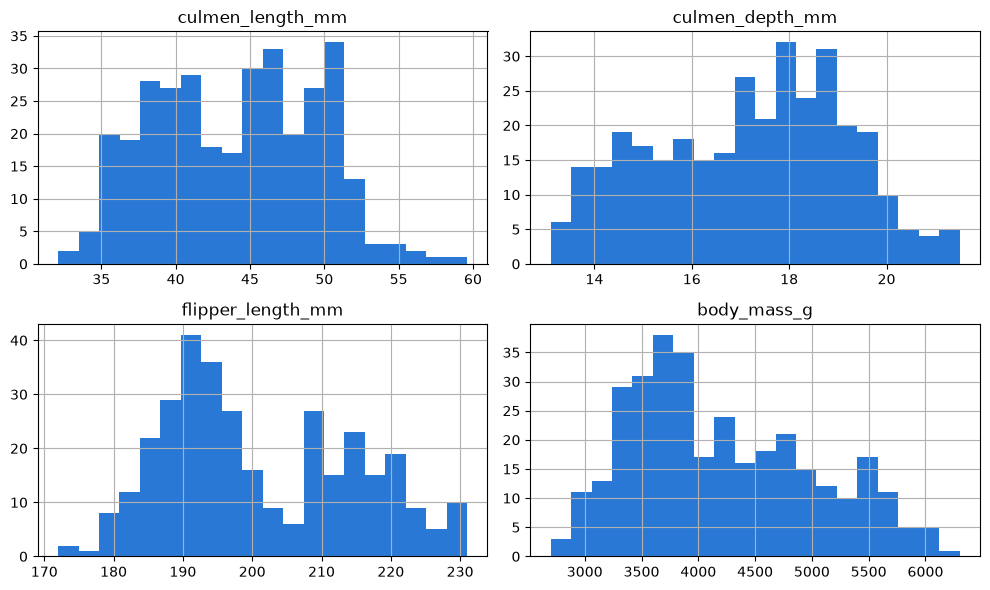

In [7]:
penguins_df[numeric_cols].hist(bins=20, figsize=(10, 6), color="#2a78d6") # plot histograms for each numeric column
plt.tight_layout() 
plt.show()

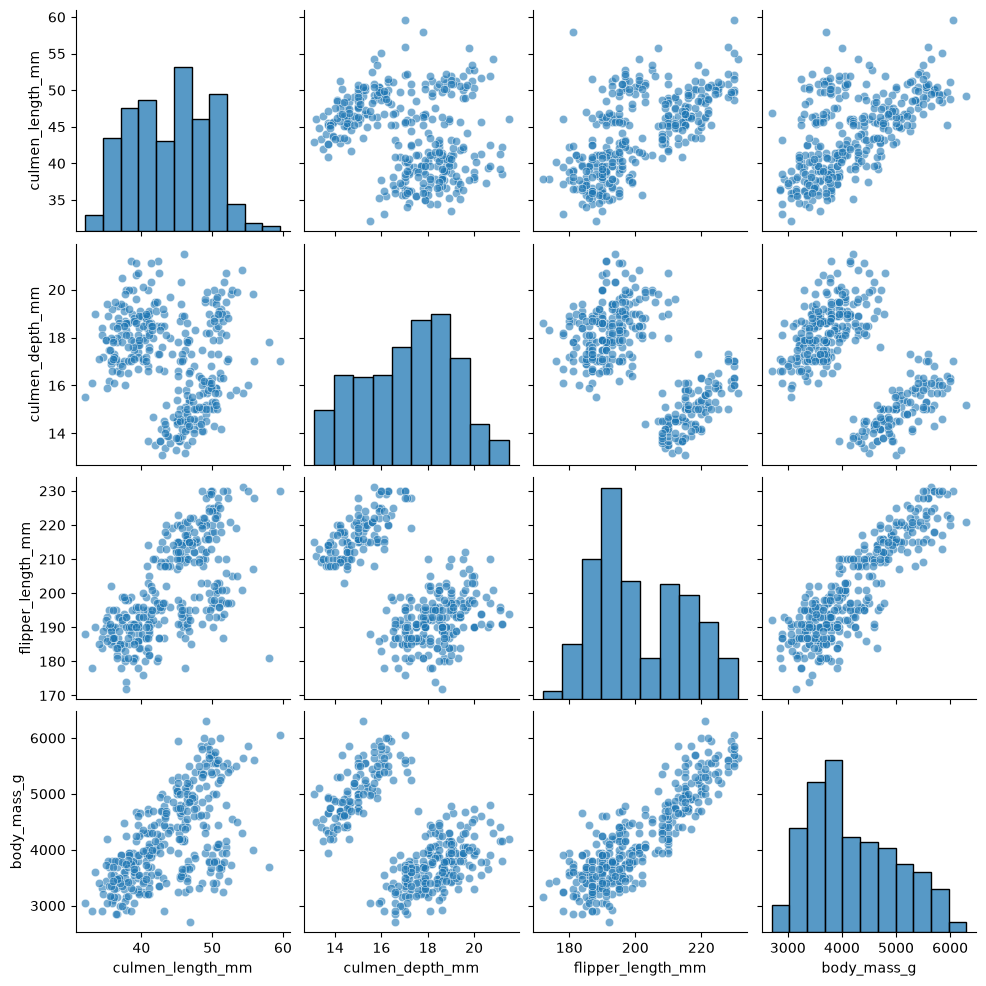

In [8]:
sns.pairplot(penguins_df[numeric_cols], diag_kind="hist", plot_kws={"alpha": 0.6}) # plot pairwise relationships between numeric columns, and display distributions on the diagonal
plt.show()

In [9]:
penguins_df[numeric_cols].corr().round(2) # display the correlation matrix for the numeric columns

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
culmen_length_mm,1.00,-0.22,0.65,0.59
culmen_depth_mm,-0.22,1.00,-0.58,-0.48
flipper_length_mm,0.65,-0.58,1.00,0.87
body_mass_g,0.59,-0.48,0.87,1.00


What I notice from these different steps:

- `sex` is almost perfectly balanced (167 males, 165 females).
- Flipper length has two clear hills in its distribution, and culmen length has several peaks. Variables that are not bell-shaped suggest a mix of different groups, which is what we are looking for.
- The scatter plots show visible clusters, especially for culmen depth, and to a lesser extent for culmen length.
- Flipper length and body mass are strongly correlated (0.87): bigger birds have longer flippers.

## 4. Pre-process the data

K-means looks for k groups of similar penguins. It places k centers in the data, assigns each penguin to its nearest center, then moves each center to the average of its group, and repeats until nothing changes.

Because it works with distances between penguins, K-means needs numbers, and the scale of each feature matters.

Therefore there are two preprocessing steps:

### 4.1 Encoding `sex` with dummies

`sex` is text (`MALE` / `FEMALE`), and K-means cannot compute a distance on text. `pd.get_dummies()` replaces a text column with one 0/1 column per category.

With only two categories, one column is enough, so I use `drop_first=True`. It keeps `sex_MALE` (1 = male, 0 = female) and drops `sex_FEMALE`, which would just repeat the same information.

I keep `sex` as a feature because it is a real characteristic of each penguin, and it can go together with its size.

In [10]:
penguins_encoded = pd.get_dummies(penguins_df, columns=["sex"], drop_first=True, dtype=int) # replace the sex column by a 0/1 dummy column: sex_MALE
penguins_encoded.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_MALE
0,39.1,18.7,181.0,3750.0,1
1,39.5,17.4,186.0,3800.0,0
2,40.3,18.0,195.0,3250.0,0
3,36.7,19.3,193.0,3450.0,0
4,39.3,20.6,190.0,3650.0,1


### 4.2 Scaling

A feature with a large spread dominates the distance. Without scaling, body mass would almost decide the clusters on its own. I use `StandardScaler` so every feature has a mean of 0 and a standard deviation of 1.

I apply it to all five columns, `sex_MALE` included, so that every feature counts equally.

In [11]:
scaler = StandardScaler() 
samples_scaled = scaler.fit_transform(penguins_encoded) # fit the scaler to the encoded data and transform it to have mean 0 and standard deviation 1

scaled_summary = pd.DataFrame(samples_scaled, columns=penguins_encoded.columns).describe().loc[["mean", "std"]] 
scaled_summary.round(2)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex_MALE
mean,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


## 5. Choose the number of clusters

K-means needs `n_clusters` in advance. I look at two things for k from 1 to 8:

- **Inertia** (elbow method): look at how tight the clusters are. It always decreases when k grows, so I look for the "elbow" where the gain becomes small.
- **Silhouette score**: how well each penguin fits its own cluster compared with the others. Higher is better (maximum is 1).

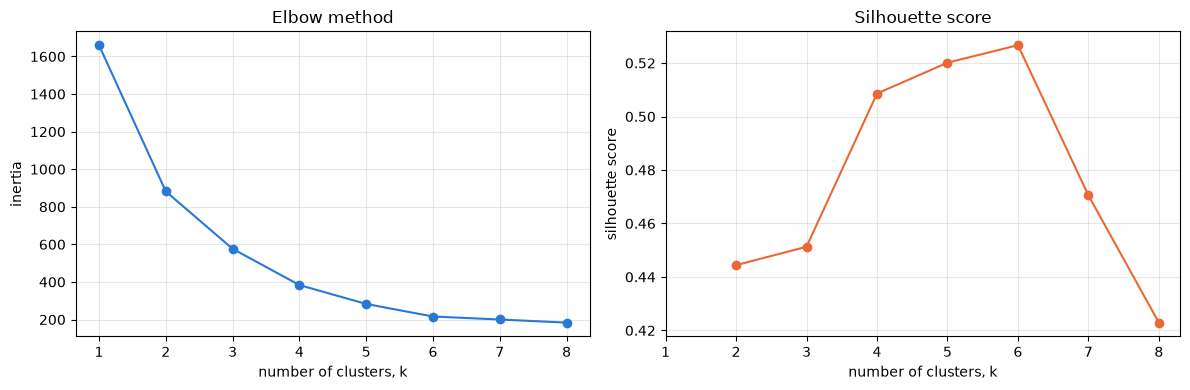

In [12]:
ks = range(1, 9) # define the range of k values to test for K-means clustering
inertias = []
silhouettes = []

for k in ks:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE) # create a KMeans model with k clusters, 10 random starting points
    model.fit(samples_scaled)
    inertias.append(model.inertia_) # store the inertia (sum of squared distances to the nearest cluster center) for each k value
    if k > 1:
        silhouettes.append(silhouette_score(samples_scaled, model.labels_)) # store the silhouette score (measure of how similar an object is to its own cluster compared to other clusters) for each k value greater than 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(ks, inertias, "-o", color="#2a78d6")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("number of clusters, k")
axes[0].set_ylabel("inertia")

axes[1].plot(range(2, 9), silhouettes, "-o", color="#eb6834")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("number of clusters, k")
axes[1].set_ylabel("silhouette score")

for ax in axes:
    ax.set_xticks(ks)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- The **elbow** is gradual: inertia falls from 1600 at k = 1 to 200s at k = 6, and then seems to flatten after.
- The **silhouette score** increases up to k = 6 around score = 0.53, its highest value, then drops sharply to around 0.47 at k = 7.

Both grahs point to a value of **k = 6**. 

That is more than the three species the researchers expect, but it fits the data. However, now `sex_MALE` is a feature, so I expect each species to split into a male group and a female group (because $\text{3 species} \times \text{2 sexes = 6}$).

## 6. Fit the final model

In [13]:
n_clusters = 6

kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE) # create a KMeans model with the chosen number of clusters
labels = kmeans.fit_predict(samples_scaled) # fit the model to the scaled data and predict the cluster labels for each sample

penguins_clustered = penguins_df.assign(cluster=labels)
penguins_clustered["cluster"].value_counts().sort_index()

cluster
0    29
1    61
2    58
3    69
4    78
5    37
Name: count, dtype: int64

### What does each cluster look like? 

To understand what each cluster represents, I compute the average of each measurement per cluster. This gives the DataFrame `stat_penguins` requested in the original task, with one row per cluster.

I use the **original values** (not the scaled ones), so the averages can be read in mm and grams. Only the four original numeric columns are kept, since `sex` is text.

In [14]:
stat_penguins = penguins_clustered.groupby("cluster")[numeric_cols].mean()

stat_penguins.round(1)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
cluster,,,,
0,47.3,17.7,192.8,3569.8
1,49.5,15.7,221.5,5484.8
2,45.6,14.2,212.7,4679.7
3,40.3,19.0,192.0,4035.1
4,37.6,17.6,187.7,3363.1
5,50.6,19.3,199.9,3953.4


## 7. Visualise the clusters

The table above gives the average of each cluster, but it does not show whether and how the clusters are really separated from each other. A plot can show this distinction more clearly.

The problem is that each penguin has five features, and a plot only has two axes. 

I use two ways to get around this: first I pick two of the original features to show the clusters in 2D (7.1), then I use a PCA to show all five at once (7.2).

### 7.1 Two original features

I plot each penguin by its culmen length and depth, colored by cluster. The black diamonds are the cluster means from `stat_penguins`.

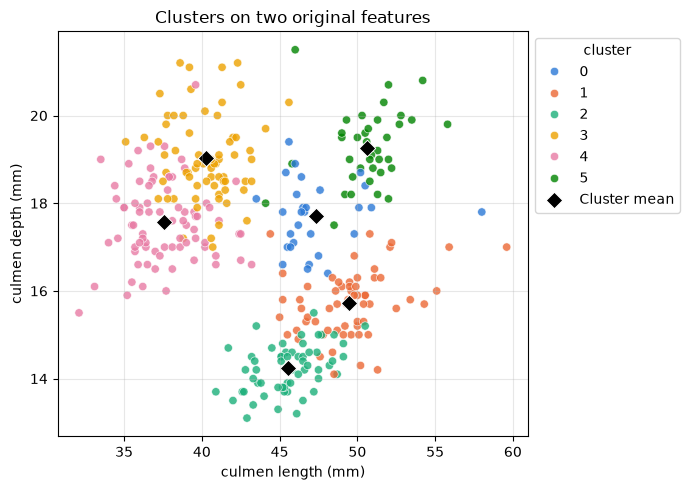

In [15]:
CLUSTER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # one fixed colour per cluster

plt.figure(figsize=(7, 5))

# Plot each penguin as a point, positioned by culmen length (x) and depth (y), points are colored by the cluster they belong to.
sns.scatterplot(
    data=penguins_clustered, x="culmen_length_mm", y="culmen_depth_mm",
    hue="cluster", palette=CLUSTER_COLORS, alpha=0.8,
)
# Add the cluster means as diamonds
sns.scatterplot(
    data=stat_penguins, x="culmen_length_mm", y="culmen_depth_mm",
    marker="D", s=70, color="black", label="Cluster mean",
)

plt.xlabel("culmen length (mm)")
plt.ylabel("culmen depth (mm)")
plt.title("Clusters on two original features")
plt.legend(title="cluster", bbox_to_anchor=(1, 1), loc="upper left") # move the legend outside the plot
plt.grid(alpha=0.3) 
plt.tight_layout()
plt.show()

The clusters overlap a bit here, because only two of the five features are shown. The other three features also help to separate the clusters.

### 7.2 All five features with PCA

To see all the features at once, I use a **PCA** (Principal Component Analysis). It combines the five features into new ones, called **PCA features**, so its axes are not in mm or grams anymore.

PCA is fitted **once** and gives back as many PCA features as it receives (here five). 

The way it works is that the first feature captures as much of the variance between penguins as possible, the second one captures as much as possible of what is left, and so on. So the PCA gives how important is each feature in the prediction of clusters.

To decide how many PCA features to keep, I fit a PCA that keeps all five and look at the variance of each:

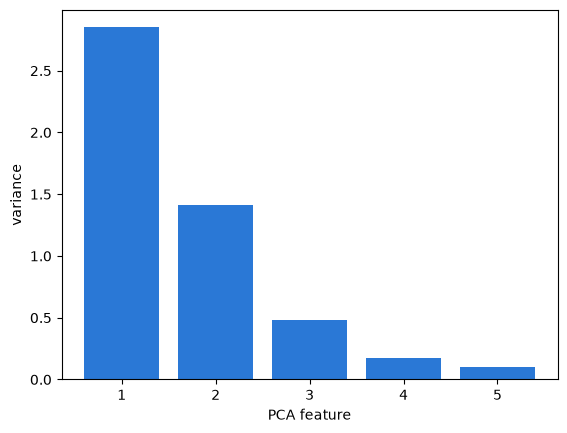

In [16]:
pca_all = PCA() # keep all the PCA features, to see how much variance each one captures
pca_all.fit(samples_scaled)

features = range(1, pca_all.n_components_ + 1) # number the PCA features from 1 to 5
plt.bar(features, pca_all.explained_variance_, color="#2a78d6")
plt.xticks(features)
plt.xlabel("PCA feature")
plt.ylabel("variance")
plt.show()

The first two PCA features carry most of the variance, and the other three add much less. So I keep only the first two features: each penguin goes from five numbers to two, which can be plotted. They are the `PCA 1` and `PCA 2` axes of the plot below.

In [17]:
pca = PCA(n_components=2) # keep only the first two PCA features
pca_coordinates = pca.fit_transform(samples_scaled) # fit the PCA model to the scaled data and transform it to obtain the coordinates of each sample in the new 2D space
pca_coordinates.shape # one row per penguin, two PCA features

(332, 2)

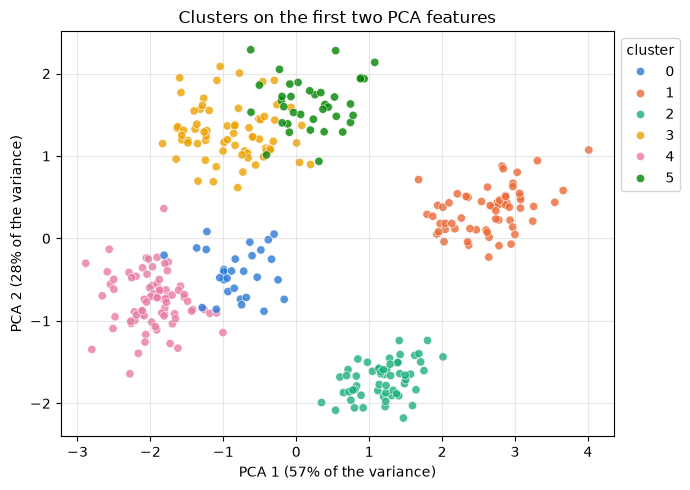

In [18]:
plt.figure(figsize=(7, 5))

sns.scatterplot(x=pca_coordinates[:, 0], y=pca_coordinates[:, 1], hue=labels, palette=CLUSTER_COLORS, alpha=0.8)

plt.xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]:.0%} of the variance)")
plt.ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]:.0%} of the variance)")
plt.title("Clusters on the first two PCA features")
plt.legend(title="cluster", bbox_to_anchor=(1, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The PCA keeps 85% of the variance of the five features. The six groups are visible: clusters 3 and 5 touch each other, and so do clusters 0 and 4, but the others are well apart.

### 7.3 Males and females in the clusters

One last check: how are males and females spread across the clusters?

In [19]:
pd.crosstab(penguins_clustered["cluster"], penguins_clustered["sex"])

sex,FEMALE,MALE
cluster,,
0,29,0
1,0,61
2,58,0
3,0,69
4,78,0
5,0,37


## 8. Conclusion

Here is a summary of the six clusters: their sex, their size, and the average of each measurement.

In [20]:
cluster_summary = stat_penguins.round(1)
cluster_summary.insert(0, "penguins", penguins_clustered["cluster"].value_counts().sort_index()) # insert number of penguins per cluster
cluster_summary.insert(0, "sex", penguins_clustered.groupby("cluster")["sex"].first()) # each cluster contains a single sex (see 7.3)
cluster_summary

,sex,penguins,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
cluster,,,,,,
0,FEMALE,29,47.3,17.7,192.8,3569.8
1,MALE,61,49.5,15.7,221.5,5484.8
2,FEMALE,58,45.6,14.2,212.7,4679.7
3,MALE,69,40.3,19.0,192.0,4035.1
4,FEMALE,78,37.6,17.6,187.7,3363.1
5,MALE,37,50.6,19.3,199.9,3953.4


**What the clusters show**

- K-means found **six clusters**, with k = 6 chosen from the elbow and the silhouette score.
- Each cluster contains **a single sex**. This is expected: `sex_MALE` is one of the features, so K-means separates the penguins by sex as well as by body type.
- In the table, the clusters come in **pairs**: a female cluster and a male cluster with a similar profile, where the male one is bigger. I found the pairs by comparing the rows by eye:
    - clusters 4 (female) and 3 (male) have the shortest bills and are light,
    - clusters 2 (female) and 1 (male) are the heaviest, with the longest flippers and the shallowest bills,
    - clusters 0 (female) and 5 (male) have long and deep bills.
- Three pairs fits with the three species the researchers expect, and each pair could be one species. But there are no species labels in the data, so I cannot check it.

**Limits to keep in mind**

- The clusters separate males from females because `sex_MALE` is a feature, and this makes it harder to relate them to species. Without the dummies asked in the original task, K-means would group the penguins by their measurements only, and the results about the species could be different. I did not test this here, but it would be a good next step.
- The pairs are my reading of the table, not something K-means computed.
- K-means likes round clusters of similar size. Clusters 0 and 5 are the smallest and touch their neighbours in the PCA plot, so some penguins are probably in the wrong group.
- k = 6 comes from the elbow and the silhouette score. It respects the researchers' "at least three species", but it is my interpretation.